In [1]:
import math
import bisect

In [2]:

# variables form the paper
param = {
"epsilon1": 0.001, #hoefding epsilon for n_z_k
"epsilon2": 0.001, #hoefding epsilon for m_x_k
"epsilon_cor": 1e-15,
"epsilon_sec": 1e-9,
"a": 6,
"b": 19
}
s_z0_u_thigter = True
Hz = 50 * 10**6 # 50 MHz
step = 10 #seconds
time_unit = 1 / Hz # seconds 
print(f"time unit: {time_unit} seconds")
k = [0.6 , 0.18]
limit = 100000
path = "QCS_2025/"
states_path = path + "states.txt"
decoy_path = path + "decoy.txt"
statesRCV_path = path + "statesRCV.txt"
bitpos_path = path + "bitpos.txt"

time unit: 2e-08 seconds


In [3]:
def entropy(probabilities):
    return -sum(p * math.log2(p) for p in probabilities if p > 0)

def bin_entropy(prob):
    p = [prob, 1-prob]
    return entropy(p)

# Functions

## extra function

In [4]:
# (A2)
def delta(value, epsilon = 1e-10):
    return math.sqrt((value * math.log10(1/epsilon))/2)

In [5]:
# (A21)
def lamda(a, b, c, d):
    if not (0 < b < 1):
        return 0
    factor1 = ((c+d)*(1-b)*b)/(c*d*math.log10(2))
    factor2 = ((c+d)/(c*d*(1-b)*b)) * (21**2/a**2)
    return math.sqrt(factor1 * math.log2(factor2))

## basic functions

In [6]:
def tao(p_k, k):
    """tao = [tao_0, tao_1] where tao_n = total prob to send n photon state"""
    tao = []
    for n in range(0, 2):
        t = 0
        for i in range(0, len(k)):
            t += p_k[i] * ((math.e**(-k[i]) * k[i]**n) / math.factorial(n))
        tao.append(t)
    return tao

In [7]:
# (A4)
def hoefding_bound(n_tot,value_k, epsilon = 1e-10):
    value_plus = value_k + delta(n_tot, epsilon)
    value_minus = value_k - delta(n_tot, epsilon)
    return value_plus, value_minus

In [8]:
# correction of (A18) with (3)
def hoefding_bound_correction(n_tot,value_k, mu, p_mu, epsilon):
    value_plus, value_minus = hoefding_bound(n_tot,value_k, epsilon)
    correction = math.e**mu / p_mu
    return value_plus * correction, value_minus * correction

## important function

In [9]:
# zero photon detection events lower bound
# with base z, equation (A19)
def s_z0_l(tao0, n_z, k, p, epsilon):
    mu1 = k[0]
    mu2 = k[1]
    n_tot = sum(n_z.values())
    # lower bound of detection events with intesity mu2 based on #detection
    # in z base
    _, n_zmu2_l = hoefding_bound_correction(n_tot, n_z['mu2'], mu2, p[1], epsilon)
    # upper bound of detection events with intesity mu2 based on #detection
    # in z base
    n_zmu1_u, _ = hoefding_bound_correction(n_tot, n_z['mu1'], mu1, p[0], epsilon)
    factor1 = tao0/(mu1 - mu2)
    term1 = mu1 * n_zmu2_l
    term2 = mu2 * n_zmu1_u
    return factor1 * (term1 - term2)

In [10]:
#equation (A14)
def s_z0_u(m_z, n_z, epsilon = 1e-10):
    #mu = k[0]
    #factor1 = 2*tao_0*((math.e**mu)/p[0])
    #term1 = m_z["mu1"]
    #term2 = delta(sum(m_z.values()), epsilon)
    #term3 = delta(sum(n_z.values()), epsilon)
    return 2 * (m_z + delta(n_z, epsilon))
    #return factor1 * (term1 + term2 + term3)

def s_z0_u_thigter(tao_0, k, p, m_z, n_z, epsilon = 1e-10):
    mu = k[0]
    factor1 = 2*tao_0*((math.e**mu)/p[0])
    term1 = m_z["mu1"]
    term2 = delta(sum(m_z.values()), epsilon)
    term3 = delta(sum(n_z.values()), epsilon)
    return factor1 * (term1 + term2 + term3)

In [11]:
#(A17)
def s_z1_l(tao, k, p, m_z, n_z, epsilon):
    mu1 = k[0]
    mu2 = k[1]
    tao0 = tao[0]
    tao1 = tao[1]
    n_tot = sum(n_z.values())
    m_tot = sum(m_z.values())
    # lower bound of detection events with intesity mu2 based on #detection
    # in z base
    _, n_zmu2_l = hoefding_bound_correction(n_tot, n_z['mu2'], mu2, p[1], epsilon)
    # upper bound of detection events with intesity mu2 based on #detection
    # in z base
    n_zmu1_u, _ = hoefding_bound_correction(n_tot, n_z['mu1'], mu1, p[0], epsilon)
    if s_z0_u_thigter:
        sz0u = s_z0_u_thigter(tao0, k, p, m_z, n_z, epsilon)
    else:
        sz0u = s_z0_u(m_tot, n_tot, epsilon)
    ## calculation
    factor1 = (tao1 * mu1)/(mu1 * (mu1- mu2))
    term1 = n_zmu2_l
    term2 = (mu2**2 / mu1**2) * n_zmu1_u
    term3 = (((mu1**2 - mu2**2)/mu1**2)*(sz0u/tao0))
    return factor1 * (term1 - term2 - term3)

In [12]:
# (A22)
def v_x1_u(tao1, m_x, k, p, epsilon):
    mu1 = k[0]
    mu2 = k[1]
    m_tot = sum(m_x.values())
    _, m_xmu2_l = hoefding_bound(m_tot,m_x['mu2'], epsilon)
    m_xmu1_u, _ = hoefding_bound(m_tot,m_x['mu1'], epsilon)
    #last changes
    #_, m_xmu2_l = hoefding_bound_correction(m_tot, m_x['mu2'], mu2, p[1], epsilon)
    #m_xmu1_u, _ = hoefding_bound_correction(m_tot, m_x['mu1'], mu1, p[0], epsilon)
    factor1 = tao1 / (mu1 - mu2)
    return max(0, factor1 * (m_xmu1_u - m_xmu2_l))

In [13]:
# (A23)
# where s_x1_l = s_z1_l
def phi_z_u(v_x1_u, s_z1_l, s_x1_l,epsilon_sec):
    if(v_x1_u < 0 or s_x1_l <= 0 or s_z1_l <= 0):
        return 0.5
    l = lamda(epsilon_sec, v_x1_u / s_x1_l, s_z1_l, s_x1_l)

    phi = v_x1_u/s_x1_l + l
    if phi < 0:
        phi = 0
    if phi > 0.5:
        phi = 0.5
    return phi

## main function

In [14]:
def length_upper(p, k, n, m, lamda_ec, param, verbose=False):
    epsilon1 = param["epsilon1"]
    epsilon2 = param["epsilon2"]
    epsilon_cor = param["epsilon_cor"]
    epsilon_sec = param["epsilon_sec"]
    a = param["a"]
    b = param["b"]
    t = tao(p, k)
    tao0 = t[0]
    tao1 = t[1]
    n_z = n['Z']
    n_x = n['X']
    m_z = m['Z']
    m_x = m['X']
    sz0l = s_z0_l(tao0, n_z, k, p, epsilon1)
    sz1l = s_z1_l(t, k, p, m_z, n_z, epsilon1)
    sz1x = s_z1_l(t, k, p, m_x, n_x, epsilon2)
    vx1u = v_x1_u(tao1, m_x, k, p, epsilon1)
    phizu = phi_z_u(vx1u, sz1x, sz1l, epsilon_sec)
    factor1 = 1 - bin_entropy(phizu)
    term1 = a * math.log2(b/epsilon_sec)
    term2 = math.log2(2/epsilon_cor)
    l = sz0l + sz1l * factor1 - lamda_ec - term1 - term2
    n_z__mu1_u, _ = hoefding_bound_correction(sum(n_z.values()), n_z['mu1'], k[0], p[0], epsilon1)
    n_z_mu2_u, _ = hoefding_bound_correction(sum(n_z.values()), n_z['mu2'], k[1], p[1], epsilon1)
    rate = l / (n_z__mu1_u + n_z_mu2_u) 
    if verbose:
        if s_z0_u_thigter:
            sz0u = s_z0_u_thigter(tao0, k, p, m_z, n_z, epsilon1)
        else:
            sz0u = s_z0_u(sum(m_z.values()), sum(n_z.values()), epsilon1)
        print("\n====== VERBOSE KEY LENGTH CALCULATION ======\n")
        print(f"is s_z0_u_thigter: {s_z0_u_thigter}\n")
        print(f"s_z0_u (vacuum upper bound)   = {sz0u:.6e}\n")
        print(f"upper bound on detections for n_z = {rate}")
        print(f"tao0 (vacuum prob)            = {tao0:.6e}")
        print(f"tao1 (single-photon prob)     = {tao1:.6e}\n")

        print(f"s_z0_l (vacuum lower bound)   = {sz0l:.6e}")
        print(f"s_z1_l (Z single lower)       = {sz1l:.6e}")
        print(f"s_x1_l (X single lower)       = {sz1x:.6e}\n")

        print(f"v_x1_u (phase error count)    = {vx1u:.6e}")
        print(f"phi_z_u (phase error)    = {phizu:.6e}")

        print(f"λ_EC (error correction)       = {lamda_ec}")
        print(f"Security penalty              = {epsilon_sec:.6e}")
        print(f"Correctness penalty           = {epsilon_cor:.6e}\n")

        print("------ FINAL KEY LENGTH ------")
        print(f"l                             = {l:.6e}")
        print("===========================================\n")
    return l, rate

# File reading functions

In [15]:
import pandas as pd

# Mapping of encoded states to bases and bits
state_map = {
    '00': ('Z', 0),  # H
    '01': ('Z', 1),  # V
    '10': ('X', 0),  # D
    '11': ('X', 1)   # A
}

#### 'mu1 > mu2 -> mu1 = '10', mu2 = '01'
decoy_map = {
    '10': 'mu1',
    '01': 'mu2'
}

In [16]:
def read_bitpos(file_path):
    """Read bit positions from CSV and return up to n absolute positions."""
    pos_data = pd.read_csv(file_path, header=None)[0].tolist()
    abs_positions = []
    i = 0
    while i < len(pos_data):
        if pos_data[i] == -1:
            abs_pos = pos_data[i+1]
            abs_positions.append(abs_pos)
            for j in range(2, 24001):
                if i+j >= len(pos_data):
                    break
                abs_pos += pos_data[i+j]
                abs_positions.append(abs_pos)
            i += 24000
        else:
            i += 1
    return abs_positions


def read_states_chunk(file_path, start=0, n=10):
    """
    Read up to `n` bytes from `file_path` starting at `start` position.
    Returns a tuple: (list of last 2 bits, new file position).
    """
    states = []
    with open(file_path, 'rb') as f:
        f.seek(start)  # move to starting position
        for _ in range(n):
            byte = f.read(1)
            if not byte:
                break  # reached EOF
            last_two_bits = byte[0] & 0b11
            states.append(format(last_two_bits, '02b'))
        new_pos = f.tell()  # remember where we stopped
    return states, new_pos


# Analysis

In [17]:
def analyze_quantum_files_chunk(states_file, decoy_file, states_rcv_file, start = 0, n = 5000):
    # Read up to n states from each file
    alice_states, new_pos_alice = read_states_chunk(states_file, start, n)
    rcv_states, new_pos_rcv = read_states_chunk(states_rcv_file, start, n)
    decoys, new_pos_decoy = read_states_chunk(decoy_file, start, n)  # still read, even if unused
    min_len = min(len(alice_states), len(rcv_states))
    alice_states = alice_states[:min_len]
    rcv_states = rcv_states[:min_len]
    if(new_pos_alice != new_pos_rcv or new_pos_alice != new_pos_decoy):
        raise ValueError("File positions do not match after reading chunk.")
    # Counters
    counts = {
        'Z':{'mu1': 0, 'mu2': 0},
        'X':{'mu1': 0, 'mu2': 0}
    }
    errors = {
        'Z':{'mu1': 0, 'mu2': 0},
        'X':{'mu1': 0, 'mu2': 0}
    }
    alice_counts = {'mu1': 0, 'mu2': 0}

    for a, r, d in zip(alice_states, rcv_states, decoys):
        alice_basis, alice_bit = state_map[a]
        rcv_basis, rcv_bit = state_map[r]
        alice_counts[decoy_map[d]] += 1
        if alice_basis == rcv_basis: # if measured with the same 
            counts[alice_basis][decoy_map[d]] += 1
            if alice_bit != rcv_bit: # if there is no error
                errors[alice_basis][decoy_map[d]] += 1
    total = len(alice_states)
    probabilities = {decoy: alice_counts[decoy]/total for decoy in ['mu1', 'mu2']}

    return {
        'error_detections': errors,
        'total_detections': counts,
        'alice_probabilities': probabilities,
        'qber_z': sum(errors['Z'].values())/sum(counts['Z'].values()),
        'qber_x': sum(errors['X'].values())/sum(counts['X'].values())
    }, new_pos_alice

In [18]:
def indices_for_step(seq, s):
    indices = []
    n = len(seq)
    k = 1
    
    while True:
        target = k * s
        # Find the index of the first element >= target
        idx = bisect.bisect_left(seq, target)
        if idx >= n:  # If we've passed the end, stop
            break
        indices.append(idx)
        k += 1
        
    return indices

def get_chunck_indices(states_pos, step_size):
    chunk_size = int(step_size / time_unit)
    chunck_indices = indices_for_step(states_pos, chunk_size)
    chunck_indices.append(len(states_pos)-1)
    return chunck_indices
states_pos = read_bitpos(bitpos_path)
chunck_indices = get_chunck_indices(states_pos, step_size = step)
print(f"total chuncks: {len(chunck_indices)}")

total chuncks: 157


In [19]:
def extract_chunck_data(chunck_indicies, first_chunck, chunck_number, verbose=False):
    lengths = []
    start_pos = 0
    datas = []
    start_pos = chunck_indicies[first_chunck]
    for i in range(chunck_number-1):
        limit = chunck_indicies[first_chunck + i + 1] - chunck_indicies[first_chunck + i]
        data, start_pos = analyze_quantum_files_chunk(states_path, decoy_path, statesRCV_path, start_pos,limit)
        datas.append(data)
    return datas

datas = extract_chunck_data(chunck_indices, 0, len(chunck_indices), True)
print(datas)

[{'error_detections': {'Z': {'mu1': 2119, 'mu2': 560}, 'X': {'mu1': 232, 'mu2': 50}}, 'total_detections': {'Z': {'mu1': 130037, 'mu2': 16972}, 'X': {'mu1': 13796, 'mu2': 1750}}, 'alice_probabilities': {'mu1': 0.8853310242335627, 'mu2': 0.11466897576643735}, 'qber_z': 0.018223374079138013, 'qber_x': 0.018139714395986106}, {'error_detections': {'Z': {'mu1': 2034, 'mu2': 516}, 'X': {'mu1': 198, 'mu2': 51}}, 'total_detections': {'Z': {'mu1': 128729, 'mu2': 16705}, 'X': {'mu1': 13988, 'mu2': 1793}}, 'alice_probabilities': {'mu1': 0.8855411945089959, 'mu2': 0.11445880549100405}, 'qber_z': 0.017533726638887744, 'qber_x': 0.015778467777707368}, {'error_detections': {'Z': {'mu1': 2169, 'mu2': 550}, 'X': {'mu1': 197, 'mu2': 58}}, 'total_detections': {'Z': {'mu1': 127980, 'mu2': 16700}, 'X': {'mu1': 14047, 'mu2': 1779}}, 'alice_probabilities': {'mu1': 0.8849772763264441, 'mu2': 0.11502272367355598}, 'qber_z': 0.018793198783522255, 'qber_x': 0.016112725894098318}, {'error_detections': {'Z': {'mu1'

### Qber plot

In [20]:
import matplotlib.pyplot as plt

def plot_qber(results_list, title="QBER over Time"):
    """
    Plots a single line for qber_z and qber_x by aggregating an array of result dicts.
    
    Args:
        results_list (list of dict): Each dict must have 'qber_z' and 'qber_x', 
                                     which can be floats or lists.
        title (str): Plot title.
    """
    qber_z_all = []
    qber_x_all = []
    
    # Aggregate QBERs over time
    for result in results_list:
        if isinstance(result['qber_z'], list):
            qber_z_all.extend(result['qber_z'])
            qber_x_all.extend(result['qber_x'])
        else:
            qber_z_all.append(result['qber_z'])
            qber_x_all.append(result['qber_x'])
    
    # X-axis is just time index
    x_axis = range(len(qber_z_all))
    
    plt.figure(figsize=(10, 6))
    plt.plot(x_axis, qber_z_all, linestyle='-', color='blue', label='qber_z')
    plt.plot(x_axis, qber_x_all, linestyle='--', color='red', label='qber_x')
    
    plt.xlabel('Time Index')
    plt.ylabel('QBER')
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


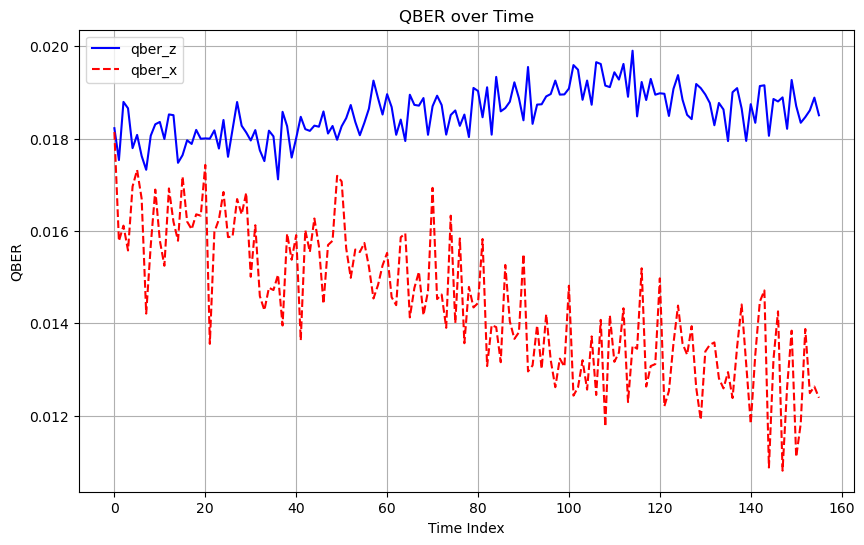

In [21]:
plot_qber(datas)

In [22]:
def key_length_chunck(datas, k, param, verbose = True):
    lengths = []
    rates = []
    errors = []   # store failing inputs

    def extract_data(data):
        p = [data["alice_probabilities"]["mu1"], data["alice_probabilities"]["mu2"]]
        n = data["total_detections"]
        m = data["error_detections"]
        lambda_ec = 1.16 * sum(n['Z'].values()) * bin_entropy(data["qber_z"])
        return p, k, n, m, lambda_ec

    for idx, data in enumerate(datas):
        try:
            p, k, n, m, lambda_ec = extract_data(data)
            print(p)
            l, r = length_upper(p, k, n, m, lambda_ec, param, verbose)
            lengths.append(l)
            rates.append(r)
        except Exception as e:
            # Optional: keep alignment
            lengths.append(None)
            rates.append(None)
            errors.append((idx, str(e)))

    return lengths, rates, errors
lengths, rates, errors = key_length_chunck(datas, k, param, True)

[0.8853310242335627, 0.11466897576643735]

====== VERBOSE KEY LENGTH CALCULATION ======

is s_z0_u_thigter: <function s_z0_u_thigter at 0x10629aac0>

s_z0_u (vacuum upper bound)   = 6.349509e+03

upper bound on detections for n_z = 0.3290618512575396
tao0 (vacuum prob)            = 5.816595e-01
tao1 (single-photon prob)     = 3.087683e-01

s_z0_l (vacuum lower bound)   = 7.621086e+04
s_z1_l (Z single lower)       = 1.015907e+05
s_x1_l (X single lower)       = 9.244655e+03

v_x1_u (phase error count)    = 1.640397e+02
phi_z_u (phase error)    = 8.014577e-03
λ_EC (error correction)       = 22398.42455740565
Security penalty              = 1.000000e-09
Correctness penalty           = 1.000000e-15

------ FINAL KEY LENGTH ------
l                             = 1.483081e+05

[0.8855411945089959, 0.11445880549100405]

====== VERBOSE KEY LENGTH CALCULATION ======

is s_z0_u_thigter: <function s_z0_u_thigter at 0x10629aac0>

s_z0_u (vacuum upper bound)   = 6.134168e+03

upper bound on detectio

In [23]:
print(lengths)
print(rates)
print(errors)

[148308.09139468364, 147217.1239111778, 144904.46153238296, 144726.70857584648, 141633.72281136052, 144567.81523577642, 148948.68930245587, 145501.4172246952, 145817.359941253, 145029.13058410268, 145263.73915453276, 149435.79199116546, 146164.59866132872, 142171.47488403745, 147800.9565582927, 144681.71431304034, 150756.08007679746, 147812.0196844312, 141601.44498186218, 147086.48922522296, 143427.01620844525, 146828.12876240507, 146648.83553631842, 146939.1132233317, 142451.0704658499, 145393.5508505109, 143424.56793135425, 142463.47993342075, 144547.4361342737, 144813.14442063263, 144620.13103040663, 142543.4941196121, 143855.8781438136, 147144.85768680152, 147435.46056691202, 150173.35651866766, 148269.08744652852, 143425.64596993924, 142730.49777062633, 145594.40186565736, 147696.9510172571, 147947.1582939041, 145133.3696419955, 145119.9654416158, 143278.0902905239, 146524.45592051983, 144109.37798019132, 142296.68624725024, 147623.57699698806, 143821.55966789383, 145656.834722865

In [24]:
import matplotlib.pyplot as plt
def plot_lengths_and_rates_separately(lengths, rates):
    clean_lengths = [0 if v is None else v for v in lengths]
    clean_rates   = [0 if v is None else v for v in rates]

    x = list(range(len(clean_lengths)))

    plt.figure()
    plt.plot(x, clean_lengths)
    plt.xlabel("Index")
    plt.ylabel("Lengths")
    plt.show()

    plt.figure()
    plt.plot(x, clean_rates)
    plt.xlabel("Index")
    plt.ylabel("Rates")
    plt.show()


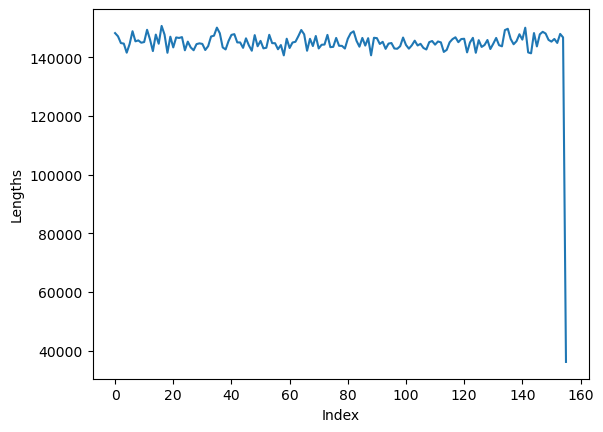

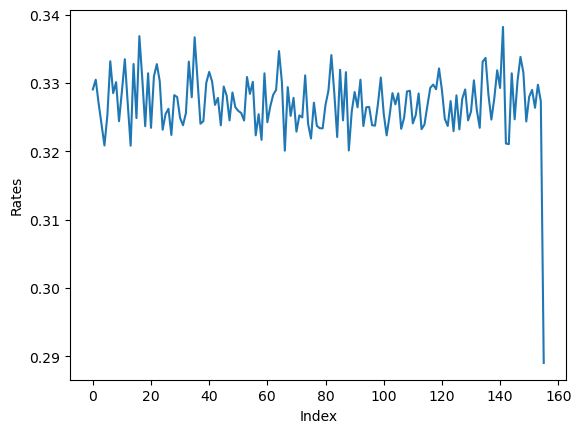

In [25]:
plot_lengths_and_rates_separately(lengths, rates)

[0.885517545900984, 0.11448245409901604]
[0.8850404554989512, 0.11495954450104885]
[0.8856215024385568, 0.11437849756144325]
[0.8852944874535232, 0.11470551254647675]
[0.885788064154719, 0.11421193584528096]
[0.8834971800797481, 0.11650281992025194]
[0.8864518899831193, 0.11354811001688071]
[0.8850153161345905, 0.11498468386540947]
[0.8855745867954525, 0.1144254132045475]
[0.8853310242335627, 0.11466897576643735]
[0.8855411945089959, 0.11445880549100405]
[0.8849772763264441, 0.11502272367355598]
[0.8852945669789024, 0.11470543302109763]
[0.8856431321900935, 0.11435686780990649]
[0.8850633609310716, 0.11493663906892843]
[0.8856726513870399, 0.1143273486129601]
[0.8861643720919106, 0.11383562790808942]
[0.885590414583065, 0.11440958541693508]
[0.8855679571910628, 0.11443204280893716]
[0.8849899465342944, 0.11501005346570563]
[0.8856203346948059, 0.11437966530519401]
[0.8852302033146079, 0.11476979668539214]
[0.8860364429713565, 0.11396355702864346]
[0.8854883266348197, 0.1145116733651803

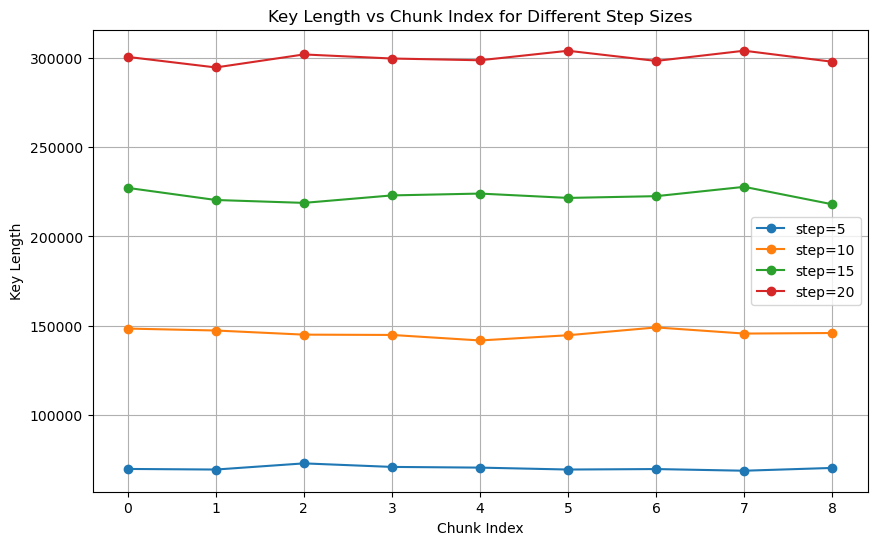

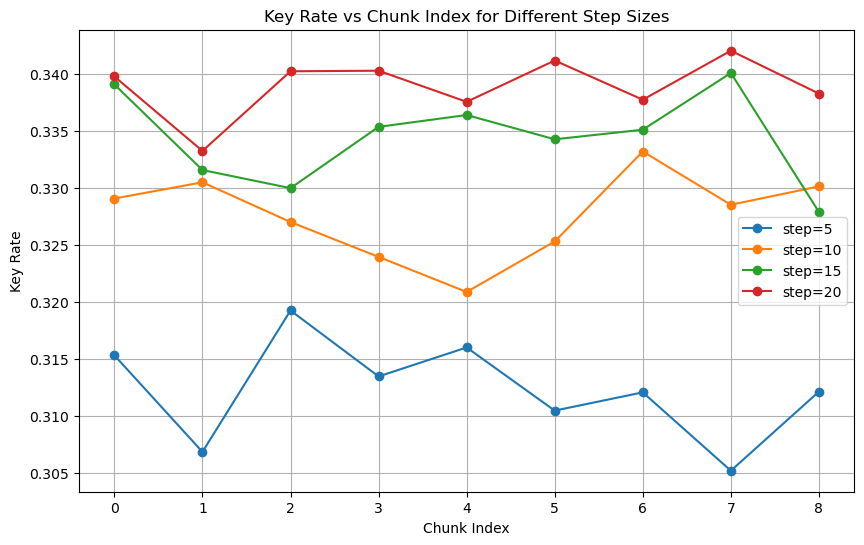

In [26]:
import matplotlib.pyplot as plt

# Different step sizes to iterate over
steps = [5, 10, 15, 20]# seconds
chunk_number = 10 # dont look at too many chuncks to avoid long computation times
# Store results for plotting
all_lengths = {}
all_rates = {}
states_pos = read_bitpos(bitpos_path)
for step in steps:
    # Get chunk indices for this step
    chunck_indices = get_chunck_indices(states_pos, step_size=step)
    
    datas = extract_chunck_data(chunck_indices, 0, 10, False)
    
    # Compute key lengths, rates, errors
    lengths, rates, errors = key_length_chunck(datas, k, param, False)
    
    # Store results
    all_lengths[step] = lengths
    all_rates[step] = rates

# Plotting
plt.figure(figsize=(10, 6))
for step in steps:
    x_axis = range(len(all_lengths[step]))  # coherent x-axis for this step size
    plt.plot(x_axis, all_lengths[step], marker='o', label=f'step={step}')

plt.xlabel('Chunk Index')
plt.ylabel('Key Length')
plt.title('Key Length vs Chunk Index for Different Step Sizes')
plt.legend()
plt.grid(True)
plt.show()

# Plotting Key Rates
plt.figure(figsize=(10, 6))
for step in steps:
    x_axis = range(len(all_rates[step]))  # coherent x-axis for this step size
    plt.plot(x_axis, all_rates[step], marker='o', label=f'step={step}')

plt.xlabel('Chunk Index')
plt.ylabel('Key Rate')
plt.title('Key Rate vs Chunk Index for Different Step Sizes')
plt.legend()
plt.grid(True)
plt.show()
